# DLBS Mini-Challenge: Object Detection im Eishockey

Autor: Silas Tschopp

**Aufgabe:** Auf Einzelbildern aus Eishockeyspielen werden Spieler (`player`), Torhüter (`goalie`), Schiedsrichter (`referee`) und Tore (`goal`) mit einem Object Detector lokalisiert und klassifiziert.

**Hypothesen (aus dem Proposal)**
- **H1:** Der AP50 der Klasse `referee` liegt auf dem Testset mindestens 5 Prozentpunkte unter dem der Klasse `player` (Mittel über drei Seeds).
- **H2:** `referee` ist unter den vier Klassen die mit dem tiefsten AP50.

**Vorgehen (Phasen)**
1. Daten, 2. Dateninspektion, 3. Gruppen-Split, 4. Baseline (COCO-Referenz, yolo26n), 5. Overfit, 6. Regularize, 7. Tune. In jeder Phase wird mit AP50 pro Klasse, mAP50–95 und Konfusionsmatrix ausgewertet.

## 0 Setup

Die Zelle prüft die Umgebung (Env `dlbs-mc`): PyTorch muss als CUDA-Build laufen und die GPU (RTX 4050 Laptop, 6 GB) sehen, sonst würde das Training auf der CPU laufen. Zusätzlich wird die Ultralytics-Version ausgegeben, damit die Ergebnisse reproduzierbar sind.

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path('..').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics

print("torch:", torch.__version__)
print("CUDA verfügbar:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "keine")
print("ultralytics:", ultralytics.__version__)

torch: 2.15.0+cu132
CUDA verfügbar: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
ultralytics: 8.4.208


## COCO-Referenz: erster Test

Bevor trainiert wird, wird das vortrainierte `yolo26n` (COCO, 80 Klassen) ohne Feintuning auf ein **Testbild** angewendet. COCO kennt nur die Klasse `person`, nicht aber Spieler, Torhüter, Schiedsrichter oder Tore. Die Zelle zeigt deshalb nur, was ein unveränderter Detektor auf Eishockeybildern liefert.

**Beobachtung (ein Beispielbild, keine Auswertung):** Alle Feldspieler und der Torhüter werden als `person` erkannt, Torhüter und Spieler sind also nicht unterscheidbar. Stock bzw. Schlittschuhe werden teils als `skis` fehlklassifiziert, das Tor wird nicht erkannt und am Rand taucht eine unsichere `person`-Box auf (Konfidenz 0.34).

**Für die spätere Referenz (Phase 4):** Spieler, Torhüter und Schiedsrichter werden in den Referenz-Labels zu einer Klasse `person` zusammengefasst, Tore entfallen (COCO hat keine passende Klasse). Die Referenz misst damit nur die Lokalisation von Personen und wird erst nach dem Gruppen-Split auf dem gemeinsamen Testset berechnet.

In [2]:
from pathlib import Path
from ultralytics import YOLO

DATA_DIR = Path("..") / "data" / "hockey_without_puck"   # relativ zum Ordner notebooks/
img_path = sorted((DATA_DIR / "test" / "images").glob("*.jpg"))[0]

model = YOLO("yolo26n.pt")          # COCO-Gewichte, beim ersten Mal automatisch geladen
print(model.names[0], len(model.names))
r = model.predict(img_path, device=0, conf=0.25)
r[0].show()


person 80

image 1/1 c:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\notebooks\..\data\hockey_without_puck\test\images\-10-10-01_12_2024_mp4-0024_jpg.rf.2c11ba4805efdd1977a7d6cd12018e46.jpg: 384x640 7 persons, 2 skiss, 16.2ms
Speed: 35.7ms preprocess, 16.2ms inference, 24.3ms postprocess per image at shape (1, 3, 384, 640)


## 2 Dateninspektion

Ziel dieser Phase ist es, die Daten zu verstehen, bevor trainiert wird: Wie sind die Klassen verteilt, wie gross sind die Objekte, und aus welchen Quellvideos stammen die Bilder? Die Ergebnisse begründen den Gruppen-Split (Phase 3) und die Wahl der Metriken.

Datensatz: Roboflow `hockey_without_puck` (YOLOv8-Format), 1'652 Bilder nach Entfernen von sechs Bildern ohne Annotation. Die mitgelieferte Aufteilung ist Train 1'242, Valid 216, Test 194.

### 2.1 Labels einlesen und Quellvideos bestimmen

Alle Labeldateien werden in eine Tabelle `boxes` (eine Zeile pro Box) eingelesen. Die YOLO-Labels enthalten pro Box die Klasse sowie Mittelpunkt, Breite und Höhe, normiert auf die Bildgrösse. Die Klassennamen kommen aus `data.yaml`.

Die Funktion `video_id()` bestimmt aus dem Dateinamen die **Quellvideo-Gruppe**. Dazu werden der Roboflow-Hash (`.rf.<hash>`), die Endung und die Frame-Nummer entfernt. Screenshots mit Zeitstempel werden nach Datum zusammengefasst, Dateien ohne erkennbaren Namen bilden die Gruppe `png_unbenannt`. Die Gruppierung ist eine Heuristik: Die grossen Gruppen (z. B. `VAN_NJD_HI_v2-…`, `InShot_…`) sind echte Videos, kleine Gruppen wie `ncaa`, `avs` oder `frame` sind eher lose Bildserien.

In [3]:
import re, yaml
from pathlib import Path

DATA_DIR = Path("..") / "data" / "hockey_without_puck"
SPLITS = ["train", "valid", "test"]

with open(DATA_DIR / "data.yaml", encoding="utf-8") as f:
    names = yaml.safe_load(f)["names"]
names = dict(enumerate(names)) if isinstance(names, list) else {int(k): v for k, v in names.items()}
print(names)


def video_id(filename):
    """Quellvideo bzw. Bildserie aus dem Dateinamen (ohne Frame-Nummer und Roboflow-Hash)."""
    b = re.sub(r"\.rf\.[0-9a-f]+\.jpg$", "", filename)
    b = re.sub(r"_(jpg|png)$", "", b)
    if re.match(r"\d{4}-\d{2}-\d{2}_\d{2}-\d{2}", b):   # Screenshots mit Zeitstempel -> nach Datum
        return b[:10]
    b = re.sub(r"[-_]?\d+-?$", "", b)                      # Frame-Nummer am Ende entfernen
    return b or "png_unbenannt"


rows = []
for split in SPLITS:
    for img in sorted((DATA_DIR / split / "images").glob("*.jpg")):
        label_file = DATA_DIR / split / "labels" / (img.stem + ".txt")
        for line in label_file.read_text().splitlines():
            c, x, y, w, h = line.split()[:5]
            rows.append(dict(split=split, image=img.name, group=video_id(img.name),
                             cls=names[int(c)], x=float(x), y=float(y), w=float(w), h=float(h)))

boxes = pd.DataFrame(rows)
images = boxes.drop_duplicates("image")[["split", "image", "group"]]
print(f"{len(images)} Bilder, {len(boxes)} Boxen, {images['group'].nunique()} Gruppen")

{0: 'goal', 1: 'goalie', 2: 'player', 3: 'referee'}
1652 Bilder, 13985 Boxen, 28 Gruppen


### 2.2 Klassenverteilung

Die Tabelle zeigt die Anzahl Boxen pro Klasse und Split, danach die Klassenanteile pro Split.

**Ergebnis:** `player` macht 77.6 % aller 13'985 Boxen aus, `referee` 9.9 %, `goalie` 6.4 %, `goal` 6.1 %. Die Klassen sind stark unausgeglichen (`player` ist 8- bis 13-mal häufiger). Deshalb wird pro Klasse der AP ausgewertet und nicht die Accuracy.

Die Anteile unterscheiden sich auch zwischen den mitgelieferten Splits, z. B. liegt `goalie` im Train bei 5.9 % und in Valid bei 8.5 %. Ein Vergleich zwischen Splits ist also nur bedingt fair.

split,train,valid,test,total,anteil_%
cls,,,,,
player,8271,1405,1178,10854,77.6
referee,1065,161,154,1380,9.9
goalie,627,160,113,900,6.4
goal,585,155,111,851,6.1


cls,goal,goalie,player,referee
split,,,,
train,5.5,5.9,78.4,10.1
valid,8.2,8.5,74.7,8.6
test,7.1,7.3,75.7,9.9


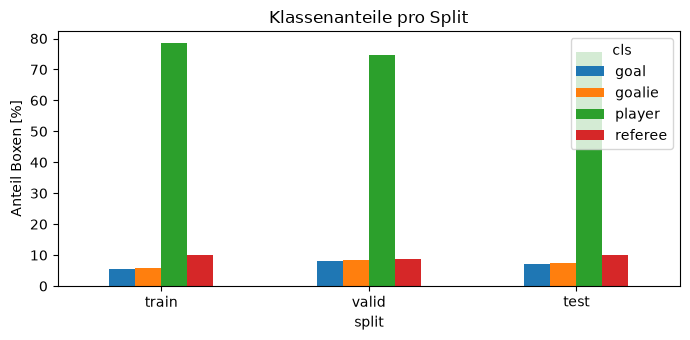

In [4]:
# Klassenverteilung pro Split
counts = pd.crosstab(boxes["cls"], boxes["split"])[SPLITS]
counts["total"] = counts.sum(axis=1)
counts["anteil_%"] = (counts["total"] / counts["total"].sum() * 100).round(1)
display(counts.sort_values("total", ascending=False))

shares = (pd.crosstab(boxes["split"], boxes["cls"], normalize="index") * 100).round(1)
display(shares.loc[SPLITS])

shares.loc[SPLITS].plot(kind="bar", figsize=(7, 3.5), ylabel="Anteil Boxen [%]", title="Klassenanteile pro Split")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 2.3 Quellvideos und Überlappung der Splits (Leakage)

Aufeinanderfolgende Frames desselben Videos sind einander sehr ähnlich. Liegen Frames eines Videos sowohl im Training als auch im Test, kennt das Modell die Szene schon, und die Testleistung wird überschätzt (Data Leakage). Die Tabelle zählt pro Gruppe, in wie vielen Splits sie vorkommt.

**Ergebnis:** Es gibt 28 Gruppen, 16 davon liegen in mehr als einem Split. 1'017 von 1'652 Bildern (62 %) stammen aus solchen Gruppen. Das Video `-10-10-01_12_2024` hat z. B. 18 Bilder im Train, 65 in Valid und 31 im Test.

**Konsequenz:** Der mitgelieferte Split wird nicht verwendet. Stattdessen wird in Phase 3 gruppiert nach Quellvideo aufgeteilt, sodass jede Gruppe nur in genau einem Split vorkommt. Da nur etwa elf Gruppen gross sind (bis 284 Bilder), lässt sich 70/15/15 nur näherungsweise erreichen.

In [5]:
# Quellvideos / Bildserien und Überlappung der Splits (Leakage-Evidenz)
group_split = pd.crosstab(images["group"], images["split"])[SPLITS]
group_split["total"] = group_split.sum(axis=1)
group_split["in_mehreren_splits"] = (group_split[SPLITS] > 0).sum(axis=1) > 1
display(group_split.sort_values("total", ascending=False))

leak_imgs = group_split.loc[group_split["in_mehreren_splits"], "total"].sum()
print(f"Gruppen: {len(group_split)}; davon in mehreren Splits: {group_split['in_mehreren_splits'].sum()}")
print(f"Bilder aus Gruppen, die über mehrere Splits verteilt sind: {leak_imgs} von {len(images)} ({leak_imgs/len(images):.0%})")

split,train,valid,test,total,in_mehreren_splits
group,,,,,
VAN_NJD_HI_v2-16_54_25_05_mp4,270,0,14,284,True
-13-13-30_11_2024_mp4,162,1,0,163,True
InShot_20250113_230703821_mp4,139,0,0,139,False
7948500339312_mp4,138,0,0,138,False
png_unbenannt,120,0,0,120,False
-10-10-01_12_2024_mp4,18,65,31,114,True
-Power-Ma-hines-01_08_2024_mp4,111,0,0,111,False
VAN_NJD_HI_v2-13_20_15_30_mp4,34,0,75,109,True
VAN_NJD_HI_v2-09_30_13_00_mp4,30,72,0,102,True


Gruppen: 28; davon in mehreren Splits: 16
Bilder aus Gruppen, die über mehrere Splits verteilt sind: 1017 von 1652 (62%)


### 2.4 Boxgrössen

Die Boxfläche wird relativ zur Bildfläche berechnet (Breite × Höhe, beide normiert) und pro Klasse zusammengefasst. Die y-Achse im Boxplot ist logarithmisch, weil sich die Werte über mehrere Grössenordnungen erstrecken.

**Ergebnis:** Der Median liegt bei `player` bei etwa 1.4 %, bei `goal` bei 1.8 %, bei `goalie` bei 1.0 % und bei `referee` bei 0.95 % der Bildfläche. Die Objekte sind klein, am kleinsten sind Schiedsrichter und Torhüter. Das spricht dafür, dass kleine Objekte schwer zu erkennen sind, und passt zu H1 und H2. Es ist aber kein Beleg dafür: Die Hypothesen werden erst mit dem AP50 auf dem Testset geprüft.

           count     min     25%     50%     75%     max
cls                                                     
goal       851.0  0.0010  0.0094  0.0179  0.0314  0.3304
goalie     900.0  0.0007  0.0055  0.0104  0.0176  0.3463
player   10854.0  0.0000  0.0068  0.0136  0.0246  0.8071
referee   1380.0  0.0004  0.0051  0.0095  0.0171  0.3903


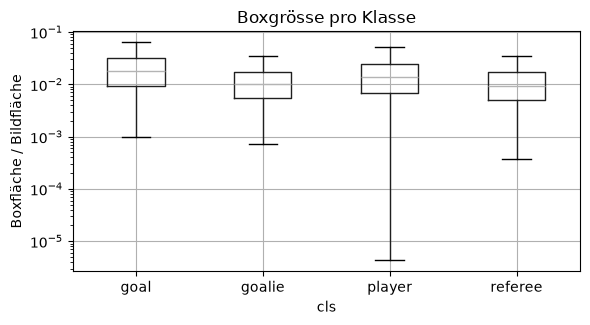

In [6]:
# Boxgrössen (relativ zur Bildfläche) pro Klasse
boxes["area"] = boxes["w"] * boxes["h"]
print(boxes.groupby("cls")["area"].describe()[["count", "min", "25%", "50%", "75%", "max"]].round(4))

boxes.boxplot(column="area", by="cls", figsize=(6, 3.5), showfliers=False)
plt.yscale("log"); plt.ylabel("Boxfläche / Bildfläche"); plt.suptitle(""); plt.title("Boxgrösse pro Klasse")
plt.tight_layout(); plt.show()

### 2.5 Beispielbilder

Vier zufällige Bilder mit den Ground-Truth-Boxen (Farbe = Klasse). Die Stichprobe dient dazu, Annotationen und Bildqualität durchzusehen (Perspektive, Auflösung, verdeckte Spieler, Überlagerungen wie Spielstand).

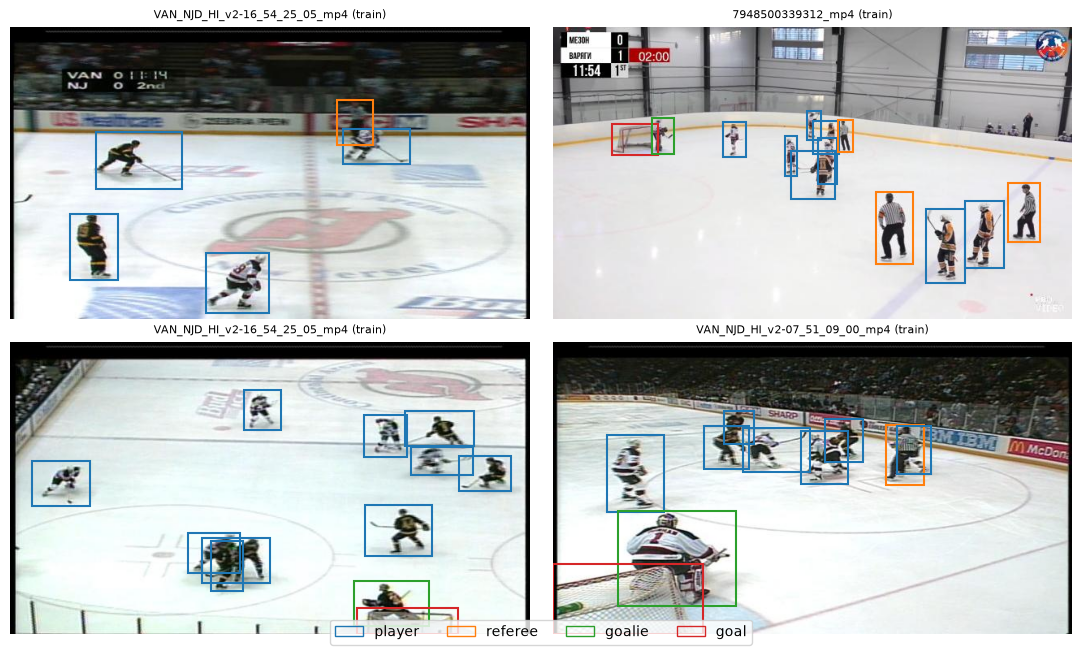

In [7]:
# Beispielbilder mit Ground-Truth-Boxen
from PIL import Image
import matplotlib.patches as patches

colors = {"player": "tab:blue", "referee": "tab:orange", "goalie": "tab:green", "goal": "tab:red"}
sample = images.sample(4, random_state=0)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    im = Image.open(DATA_DIR / row["split"] / "images" / row["image"])
    W, H = im.size
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{row['group']} ({row['split']})", fontsize=8)
    for _, b in boxes[boxes["image"] == row["image"]].iterrows():
        ax.add_patch(patches.Rectangle(((b.x - b.w/2) * W, (b.y - b.h/2) * H), b.w * W, b.h * H,
                                       fill=False, edgecolor=colors[b.cls], linewidth=1.5))
handles = [patches.Patch(edgecolor=c, fill=False, label=k) for k, c in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=4)
plt.tight_layout(); plt.show()